In [10]:
import numpy as np
import matplotlib.pyplot as plt
import math

(100,)
The variance is 44


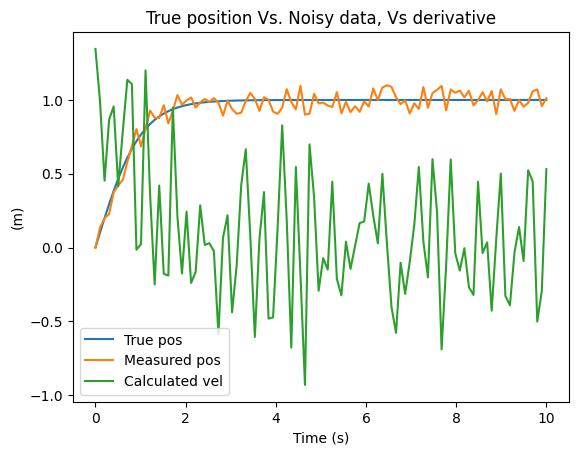

In [15]:
# Write a ROS node that subscribes to /vicon_data/pos
# For the vicon data there are packages that subscribe to the 
# vicon system and publish topics with a custom message.
# Plot the position as you receive it

# Print the mean, variance of the position 

# Do a fourier transform on the position vector w.r.t time (windowing)

# IMPORTANT PART!!!
# We want velocity from the vicon position. This means taking the numerical
# derivative. Try doing this with `np.gradient`. Ideally this would be nice and smooth.

def deriv_tanh(x):
    sech = 1 / np.cosh(x) # sech
    return sech**2

time = np.linspace(0,10,100).flatten()

# We won't actually have this data :(
true_vicon_pos = np.tanh(time) * np.ones((1,100)).flatten()
true_vicon_vel = deriv_tanh(time) **2


# We get this (noisy!) position data.
noise = np.random.uniform(-0.1,0.1,(1,100)).flatten() # Fake centered Gaussian noise.
vicon_data = true_vicon_pos + noise

# We can find the robot velocity in the vicon room by taking a
# numerical derivative.
derivative = np.gradient(vicon_data,time)

fig, ax = plt.subplots()
plt.plot(time,true_vicon_pos)
plt.plot(time,vicon_data)
plt.plot(time,derivative)

ax.legend(['True pos', 'Measured pos', 'Calculated vel'])
ax.set_xlabel("Time (s)")
ax.set_ylabel("(m)")
plt.title("True position Vs. Noisy data, Vs derivative")
print(derivative.shape)

print("The variance is 44")
